In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

bigsize = (10, 7, ) # /2.54 = cm2inch
labelrot = 0

In [2]:
import re
from concurrent.futures import ThreadPoolExecutor
from glob import glob
from os.path import basename, dirname

# ---------------------------------------------------------------- parsing ---

_FIELD_RE = re.compile(r"^\s*([A-Za-z][^:]*?)\s*:\s*(.*?)\s*$")
_MISSING = {"", "-", "n/a", "na", "none", "null"}


def _to_bool(v):
    return v.strip().lower() in {"yes", "true", "1"}


def _to_seconds(v):
    return float(v.split()[0])


# report label -> (dict key, caster)
_FIELDS = {
    "Item Index":                          ("item_index", int),
    "JSON Path":                           ("json_path", str),
    "Embedding Path":                      ("embedding_path", str),
    "JSON Valid":                          ("json_valid", _to_bool),
    "Sequence Similarity (Gestalt)*":      ("sequence_similarity", float),
    "Levenshtein Distance (minified)":     ("levenshtein_distance", int),
    "Levenshtein Similarity (minified)*":  ("levenshtein_similarity", float),
    "App Match":                           ("app_match", _to_bool),
    "Activity Match":                      ("activity_match", _to_bool),
    "Component Count (GT)":                ("component_count_gt", int),
    "Component Count (Pred)":              ("component_count_pred", int),
    "Class Accuracy*":                     ("class_accuracy", float),
    "Average Bounds IoU*":                 ("average_bounds_iou", float),
    "Execution Time":                      ("execution_time", _to_seconds),
}


def parse_metrics_from_report_file(path):
    """Parse an evaluation report into a flat dict of metrics.

    The side-by-side JSON dump is skipped entirely; missing or unparsable
    values become None so every report yields the same set of keys.
    """
    with open(path, "r", encoding="utf-8", errors="replace") as fh:
        text = fh.read()

    # header (above the JSON table) + everything below "METRICS:"
    head, sep, tail = text.partition("GROUND TRUTH")
    relevant = head + tail.partition("METRICS:")[2] if sep else text

    out = {key: None for key, _ in _FIELDS.values()}
    for line in relevant.splitlines():
        match = _FIELD_RE.match(line)
        if match is None:
            continue
        label, raw = match.group(1), match.group(2)
        if label not in _FIELDS:
            continue
        key, cast = _FIELDS[label]
        if raw.lower() in _MISSING:
            continue
        try:
            out[key] = cast(raw)
        except (ValueError, IndexError):
            out[key] = None
    return out


def _process_report(g):
    # e.g. "reconstructions_4096_avg/0_report.txt" -> "4096_avg"
    # e.g. "reconstructions_4096_last/0_report.txt" -> "4096_last"
    # keeping the pooling suffix (avg/last) in the key prevents the
    # 4096_avg and 4096_last folders from clobbering each other.
    dimensions = dirname(g).removeprefix("reconstructions_")
    idx = basename(g).split("_")[0]
    return (dimensions, idx), parse_metrics_from_report_file(g)


# ------------------------------------------------------------------- entry ---

def parse_reconstruction_dataset(pattern="reconstructions*/*", max_workers=None):
    """Glob reconstruction report files and parse them in parallel.

    Returns a dict keyed by (dimensions, idx) -> metrics dict.
    """
    paths = [g for g in glob(pattern) if "report" in g]

    results = {}
    with ThreadPoolExecutor(max_workers=max_workers) as pool:
        for key, metrics in pool.map(_process_report, paths, chunksize=8):
            results[key] = metrics

    return results

In [3]:
results = parse_reconstruction_dataset()

df = pd.DataFrame(results).T
df.index.names = ['dim', 'idx']

## Filters

In [4]:
# keep only same indices among all samples
# idx_per_dim = df.index.to_frame(index=False).groupby('dim')['idx'].apply(set)
# common_idx = set.intersection(*idx_per_dim)
# df = df.loc[df.index.get_level_values('idx').isin(common_idx)]

# remove overtrained adapter
#df = df[(df.index.get_level_values('dim') != '128x4096_avg')]

# Take only validation set jsons into account
# df = df[(df.index.get_level_values('idx').astype(int) > 11504)]

# Take only valid jsons into account across all dimensions
# df = df[df.groupby(level='idx')['json_valid'].transform('all')]

In [5]:
df

item_index  \
dim                                                         idx                
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b 0              0   
                                                            10000      10000   
                                                            10002      10002   
                                                            10003      10003   
                                                            10004      10004   
...                                                                      ...   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b    9998        9998   
                                                            9999        9999   
                                                            999          999   
                                                            99            99   
                                                            9              9   

                                                                                              json_path  \
dim                                                         idx                                           
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b 0          ../rico-data/data/layouts/0.json   
                                                            10000  ../rico-data/data/layouts/10000.json   
                                                            10002  ../rico-data/data/layouts/10002.json   
                                                            10003  ../rico-data/data/layouts/10003.json   
                                                            10004  ../rico-data/data/layouts/10004.json   
...                                                                                                 ...   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b    9998    ../rico-data/data/layouts/9998.json   
                                                            9999    ../rico-data/data/layouts/9999.json   
                                                            999      ../rico-data/data/layouts/999.json   
                                                            99        ../rico-data/data/layouts/99.json   
                                                            9          ../rico-data/data/layouts/9.json   

                                                                                      embedding_path  \
dim                                                         idx                                        
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b 0          embeddings_128x4096_avg/0.npz   
                                                            10000  embeddings_128x4096_avg/10000.npz   
                                                            10002  embeddings_128x4096_avg/10002.npz   
                                                            10003  embeddings_128x4096_avg/10003.npz   
                                                            10004  embeddings_128x4096_avg/10004.npz   
...                                                                                              ...   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b    9998      embeddings_8x4096_avg/9998.npz   
                                                            9999      embeddings_8x4096_avg/9999.npz   
                                                            999        embeddings_8x4096_avg/999.npz   
                                                            99          embeddings_8x4096_avg/99.npz   
                                                            9            embeddings_8x4096_avg/9.npz   

                                                                  json_valid  \
dim                                                         idx                
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b 0           True   
                                        

In [6]:
df.columns

Index(['item_index', 'json_path', 'embedding_path', 'json_valid',
       'sequence_similarity', 'levenshtein_distance', 'levenshtein_similarity',
       'app_match', 'activity_match', 'component_count_gt',
       'component_count_pred', 'class_accuracy', 'average_bounds_iou',
       'execution_time'],
      dtype='str')

In [7]:
df.groupby("dim").count()

,item_index,json_path,embedding_path,json_valid,sequence_similarity,levenshtein_distance,levenshtein_similarity,app_match,activity_match,component_count_gt,component_count_pred,class_accuracy,average_bounds_iou,execution_time
dim,,,,,,,,,,,,,,
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261


In [8]:
import re
from glob import glob

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.container import BarContainer


FIRST_NUMBER_PRIORITY = {
    4096: 0,
    4: 1,
    8: 2,
    128: 3,
}


def first_number_sort_key(value):
    text = str(value)
    match = re.search(r"\d+", text)

    if match is None:
        return 2, float("inf"), text.casefold()

    first_number = int(match.group())

    if first_number in FIRST_NUMBER_PRIORITY:
        return (
            0,
            FIRST_NUMBER_PRIORITY[first_number],
            text.casefold(),
        )

    return (
        1,
        first_number,
        text.casefold(),
    )


def plot_bool_grouped(
    df: pd.DataFrame,
    bool_cols: list,
    by: str,
    as_percentage: bool = True,
    xlabel: str | None = None,
    title: str | None = None,
    show_legend: bool = True,
):
    data = (
        df.reset_index()
        if by in df.index.names and by not in df.columns
        else df.copy()
    )

    if as_percentage:
        grouped = data.groupby(by)[bool_cols].mean() * 100
        errors = data.groupby(by)[bool_cols].sem().fillna(0) * 100
        default_xlabel = "Anteil True (%)"
        value_format = "%.1f"
    else:
        grouped = data.groupby(by)[bool_cols].sum()
        errors = data.groupby(by)[bool_cols].std().fillna(0)
        default_xlabel = "Anzahl True"
        value_format = "%.0f"

    sorted_labels = sorted(
        grouped.index,
        key=first_number_sort_key,
    )

    grouped = grouped.reindex(sorted_labels)
    errors = errors.reindex(sorted_labels)

    ax = grouped.plot(
        kind="barh",
        xerr=errors,
        capsize=4,
        figsize=bigsize,
        legend=show_legend,
    )

    for container in ax.containers:
        if isinstance(container, BarContainer):
            ax.bar_label(
                container,
                fmt=value_format,
                padding=3,
                fontsize=8,
            )

    ax.set_xlabel(
        xlabel if xlabel is not None else default_xlabel
    )
    ax.set_ylabel(by)
    ax.set_title(
        title
        if title is not None
        else f'True-Verteilung gruppiert nach "{by}"'
    )
    ax.tick_params(
        axis="y",
        labelrotation=labelrot,
    )

    ax.invert_yaxis()

    if show_legend:
        ax.legend(
            bbox_to_anchor=(1.05, 1),
            loc="upper left",
        )

    plt.tight_layout()
    plt.show()

def show_stats(column: str, by: str = "dim"):
    global df

    df[column] = pd.to_numeric(
        df[column],
        errors="coerce",
    )

    # "dim" is an index level (df has a ("dim", "idx") MultiIndex), so it
    # cannot be addressed as df["dim"] -- fall back to the index level.
    labels = (
        df.index.get_level_values(by)
        if by in df.index.names and by not in df.columns
        else df[by]
    )
    label_values = pd.Series(labels, index=df.index)

    sorted_labels = sorted(
        label_values.dropna().unique(),
        key=first_number_sort_key,
    )

    boxplot_data = [
        df.loc[(label_values == label).to_numpy(), column].dropna()
        for label in sorted_labels
    ]

    fig, ax = plt.subplots(figsize=bigsize)

    ax.boxplot(
        boxplot_data,
        tick_labels=sorted_labels,
        showfliers=False,
        vert=False,
    )

    ax.set_xlabel(column)
    ax.set_ylabel(by)
    ax.set_title(f'{column} gruppiert nach "{by}"')
    ax.tick_params(
        axis="y",
        labelrotation=labelrot,
    )

    ax.invert_yaxis()

    plt.tight_layout()
    plt.show()

    grouped_column = df.groupby(
        by,
        sort=False,
    )[column]

    desc_stats = grouped_column.describe()
    desc_stats["median"] = grouped_column.median()
    desc_stats["IQR"] = (
        grouped_column.quantile(0.75)
        - grouped_column.quantile(0.25)
    )

    desc_stats = desc_stats.reindex(sorted_labels)

    print(desc_stats)


In [9]:
df.groupby('dim').count()

,item_index,json_path,embedding_path,json_valid,sequence_similarity,levenshtein_distance,levenshtein_similarity,app_match,activity_match,component_count_gt,component_count_pred,class_accuracy,average_bounds_iou,execution_time
dim,,,,,,,,,,,,,,
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261


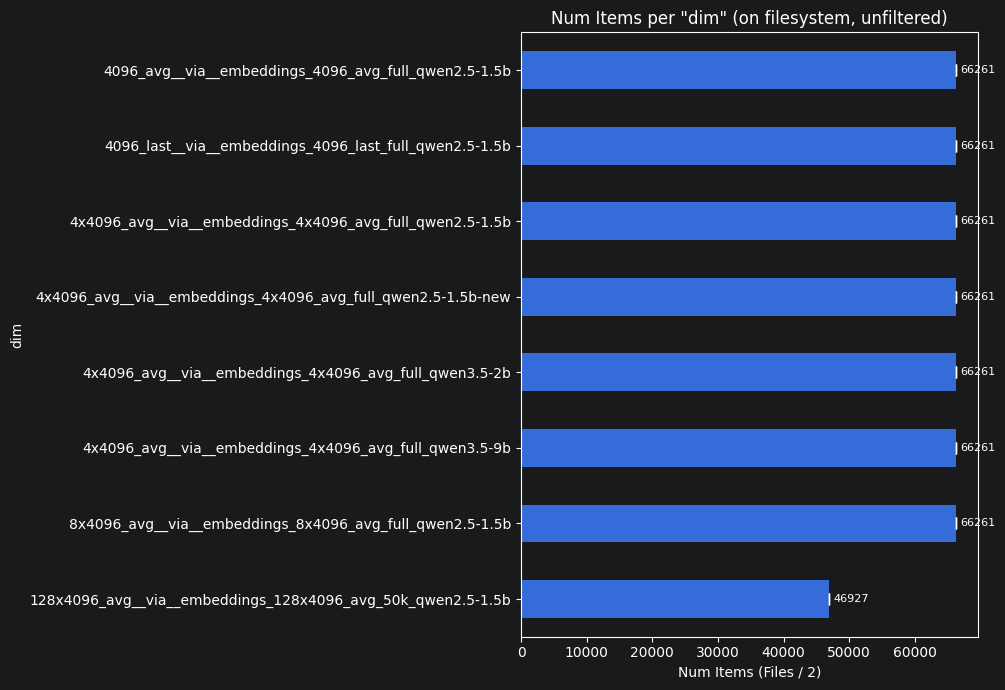

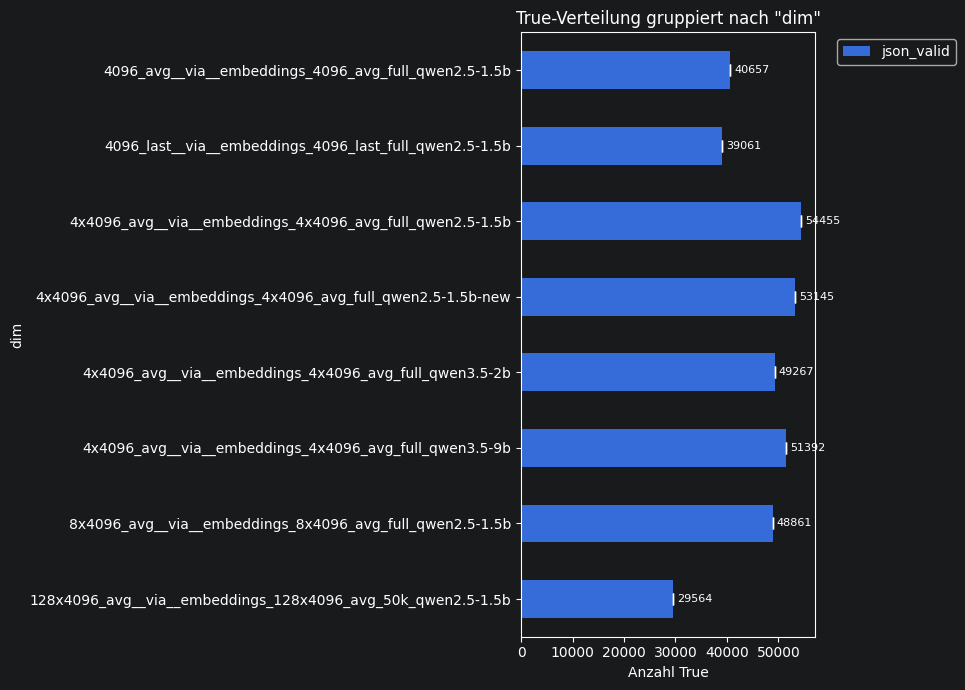

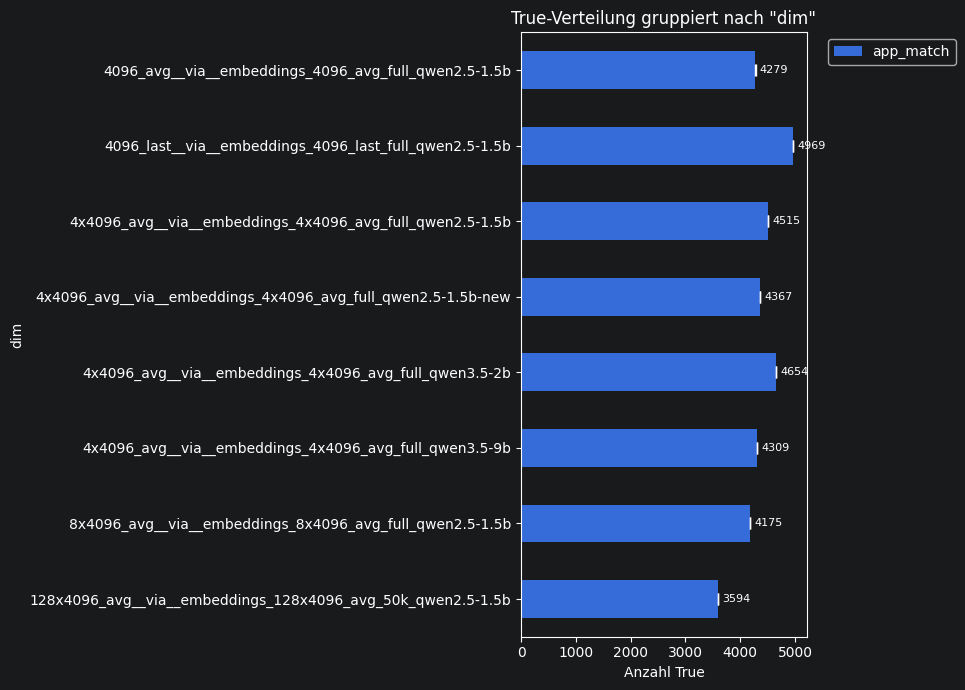

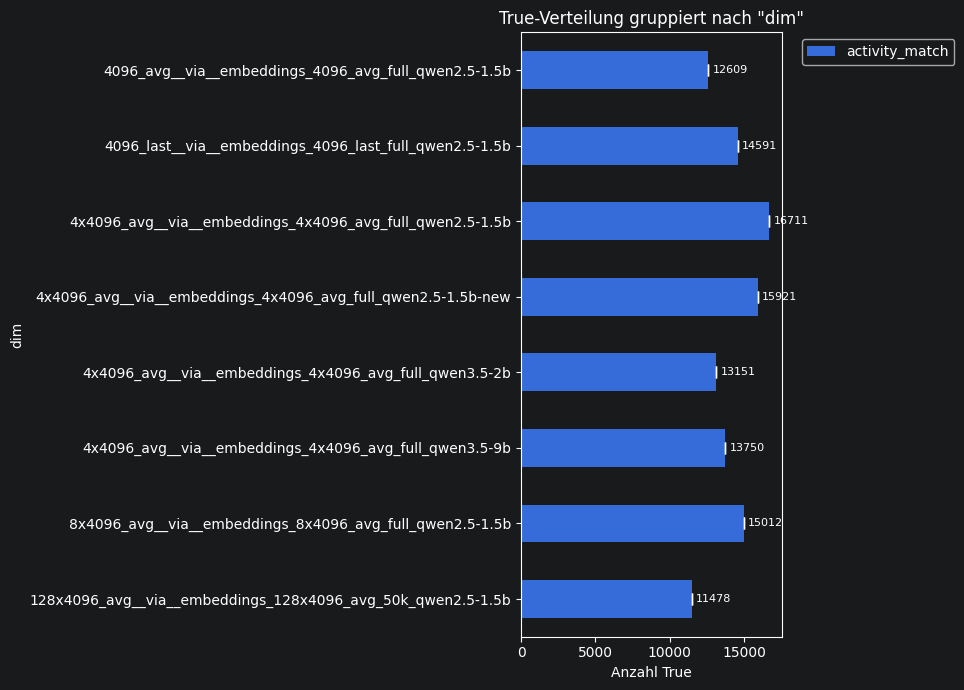

In [10]:
file_counts_df = (
    pd.Series(
        {
            directory.removeprefix("reconstructions_"):
                len(glob(f"{directory}/*")) // 2
            for directory in glob("reconstructions_*")
        },
        name="num_items",
    )
    .rename_axis("dim")
    .reset_index()
)


plot_bool_grouped(
    file_counts_df,
    ["num_items"],
    by="dim",
    as_percentage=False,
    xlabel="Num Items (Files / 2)",
    title='Num Items per "dim" (on filesystem, unfiltered)',
    show_legend=False,
)

plot_bool_grouped(
    df,
    ["json_valid"],
    by="dim",
    as_percentage=False,
)

plot_bool_grouped(
    df,
    ["app_match"],
    by="dim",
    as_percentage=False,
)

plot_bool_grouped(
    df,
    ["activity_match"],
    by="dim",
    as_percentage=False,
)

## Boxplot: Sequence Similarity

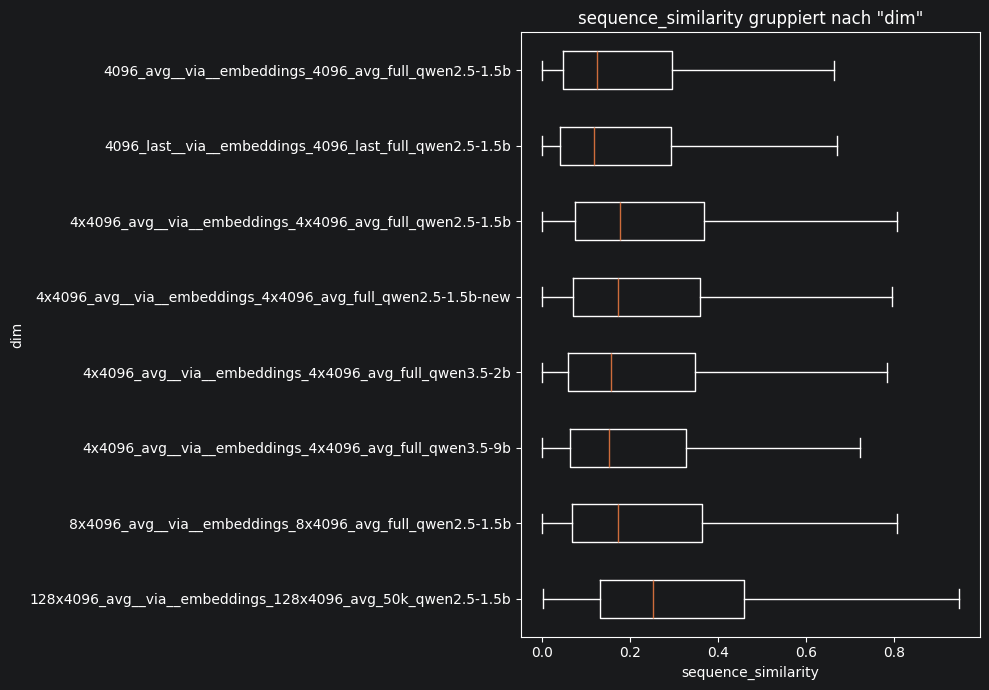

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                                  mean  \
dim                                                                      
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          0.220665   
4096_last__via__embeddings_4096_last_full_qwen2

In [11]:
show_stats('sequence_similarity')

## Boxplot: Levenshtein Distance

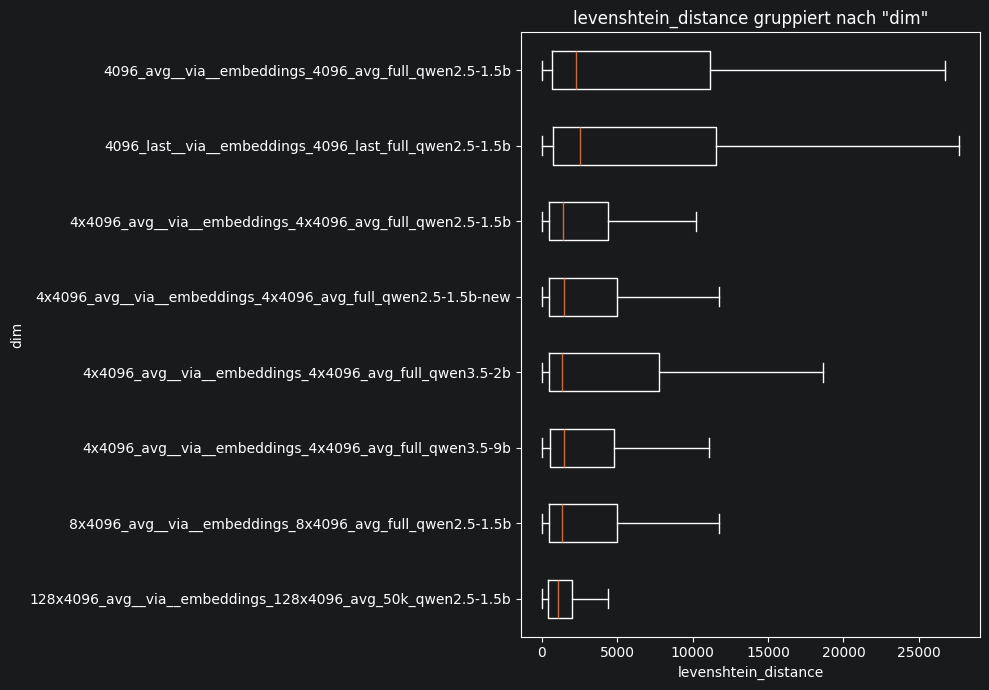

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                                     mean  \
dim                                                                         
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          5347.506361   
4096_last__via__embeddings_4096_last_f

In [12]:
show_stats('levenshtein_distance')

## Boxplot: Levenshtein Similarity

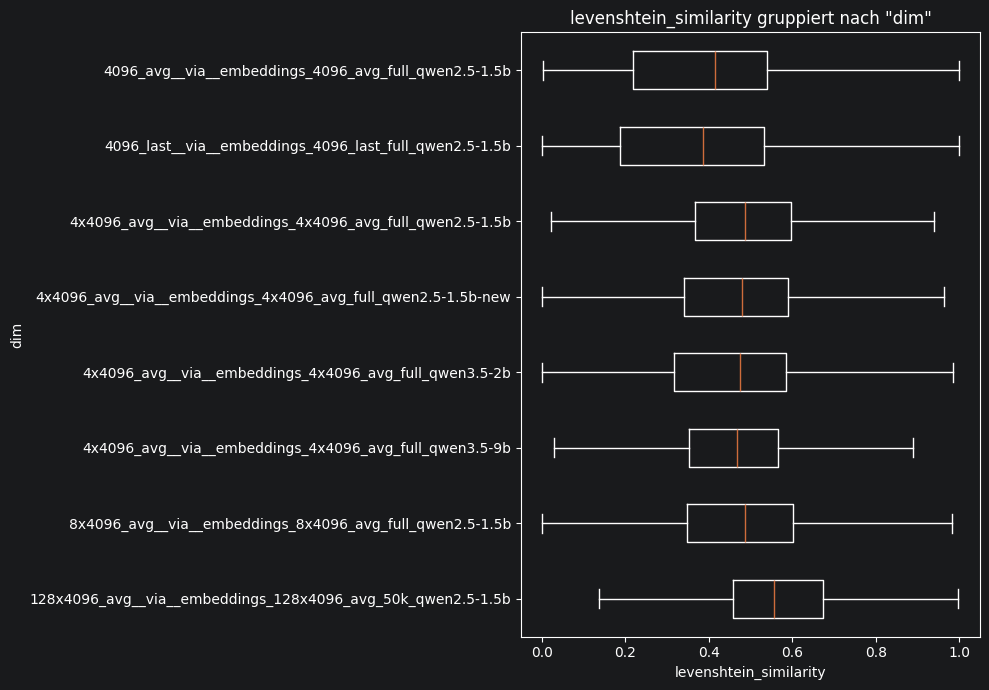

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                                  mean  \
dim                                                                      
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          0.413917   
4096_last__via__embeddings_4096_last_full_qwen2

In [13]:
show_stats('levenshtein_similarity')

## Boxplot: Class Accuracy

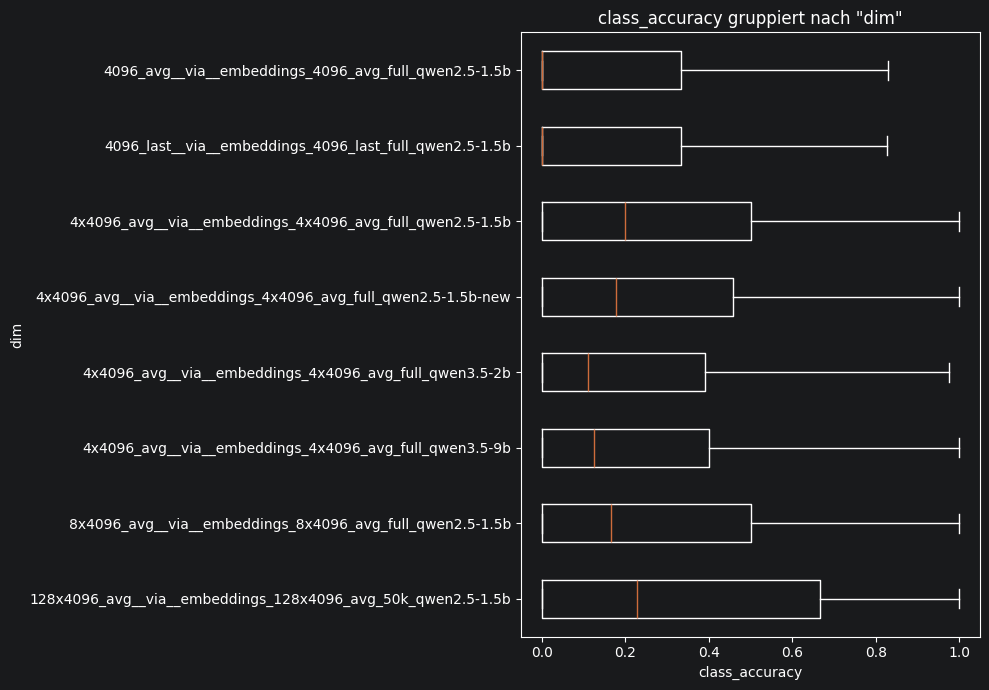

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                                  mean  \
dim                                                                      
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          0.214169   
4096_last__via__embeddings_4096_last_full_qwen2

In [14]:
show_stats('class_accuracy')

## Boxplot: Average Bounds IoU

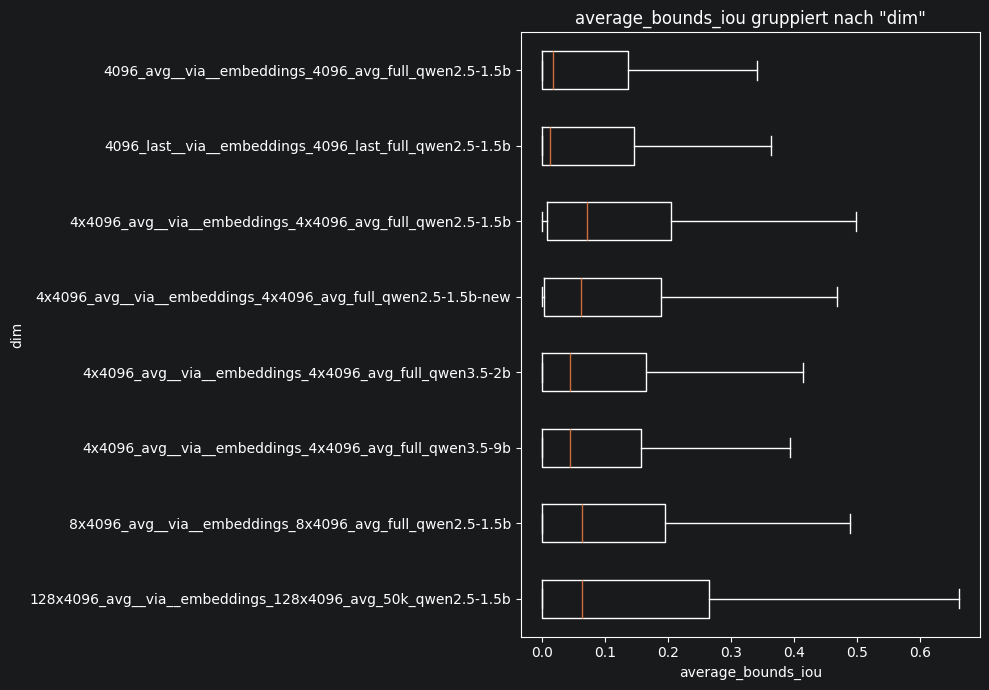

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                                  mean  \
dim                                                                      
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          0.147447   
4096_last__via__embeddings_4096_last_full_qwen2

In [15]:
show_stats('average_bounds_iou')

## Repaired JSON